# 02 · Themennetz: Wie hängen die Themen von 20 Minuten zusammen?

Ähnlich wie David Kriesel bei SpiegelMining wollen wir aus den Artikeln eine Landkarte der Themen bauen. Wir beginnen mit
einem **Two-Mode-Netz**: Artikel auf der einen Seite, Keywords auf der anderen. Durch **Projektion** entsteht daraus ein
**One-Mode-Netz**, in dem nur noch Keywords Knoten sind. Zwei Keywords sind verbunden, wenn sie im selben Artikel vorkommen.

```
Artikel A ── Corona, BAG, Massnahme          Corona ── BAG
Artikel B ── Corona, Schule                   │   ╲
                                ──────────►  Massnahme  Schule
```

Als Kantengewicht verwenden wir Newmans gewichtete Projektion: Ein Artikel mit vielen Keywords zählt pro Paar weniger
als einer mit wenigen. Zum Vergleich gibt es die einfache Kookkurrenz (Anzahl gemeinsamer Artikel) und den Salton-Kosinus.

Mit dem Netz wollen wir drei Vermutungen prüfen:

- **H1:** In Krisenjahren (2020 Covid, 2022 Ukraine) konzentriert sich die Berichterstattung auf wenige Begriffe.
  Das Netz ist dann stärker zentralisiert.
- **H2:** Die Ressorts sind thematische Silos. Nur wenige Begriffe verbinden sie.
- **H3:** Neue Verbindungen zwischen Themen lassen sich aus dem bisherigen Netz vorhersagen. Verfahren, die auf
  gemeinsame Nachbarn achten (Adamic-Adar), sollten dabei besser sein als Preferential Attachment.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))  # Notebook liegt in src/
import daten
import grafik
import netzwerk as nw

# Hauptdatenbank, sobald Keywords und Personen gebildet sind, sonst die Kopie
# data/articles_snapshot.sqlite. Andere Datenbank: Umgebungsvariable SAN_DB.
DB = daten.standard_db()
GRAPHEN = daten.ROOT / "Graphen"

grafik.stil()
pd.set_option("display.max_colwidth", 100)
print("Datenbank:", DB)

Datenbank: C:\Users\elias\Desktop\FHNW\SAN\SAN_20_Minuten\data\articles.sqlite


Die folgenden Parameter bestimmen, welche Knoten und Kanten ins Netz kommen:

- `MIN_DF`: In so vielen Artikeln muss ein Keyword mindestens vorkommen. Seltene Begriffe tragen kaum Struktur und blähen das Netz auf.
- `MIN_ANZAHL`: So viele gemeinsame Artikel braucht eine Kante. Eine einzelne gemeinsame Nennung kann Zufall sein.
- `BACKBONE_K`: Für den Export nach Gephi behalten wir pro Knoten nur die stärksten Kanten.

Liveticker lassen wir weg (`ohne_ticker=True` in `nw.keyword_zuordnung`), weil sie viele unzusammenhängende Themen in
einer URL bündeln (Notebook 01, Abschnitt 3).

In [2]:
MIN_DF = 20
MIN_ANZAHL = 3
GEWICHT = "newman"
BACKBONE_K = 10

artikel = daten.load_articles(DB)
keywords = daten.load_keywords(DB)
if len(artikel) < 20000:  # kleine Test-Datenbank: Schwellen herabsetzen
    MIN_DF, MIN_ANZAHL = 5, 2
JAHRE = sorted(artikel["jahr"].dropna().unique())
print(f"{len(artikel):,} Artikel aus den Jahren {JAHRE[0]} bis {JAHRE[-1]}")
print(f"MIN_DF = {MIN_DF}, MIN_ANZAHL = {MIN_ANZAHL}, Gewicht = {GEWICHT}")

165,151 Artikel aus den Jahren 2020 bis 2026
MIN_DF = 20, MIN_ANZAHL = 3, Gewicht = newman


## 1. Das Two-Mode-Netz Artikel–Keyword

Bevor wir projizieren, schauen wir das Ausgangsnetz an. Seine Gradverteilung bestimmt, wie die Projektion aussieht:
Ein Keyword, das in 5'000 Artikeln vorkommt, bekommt in der Projektion sehr viele Nachbarn.

Pro Artikel speichert die Keyword-Schicht höchstens 8 Keywords. Nach dem Filter `MIN_DF` sollten es etwas weniger sein.
Bei den Keywords erwarten wir wieder die ungleiche Verteilung aus Notebook 01.

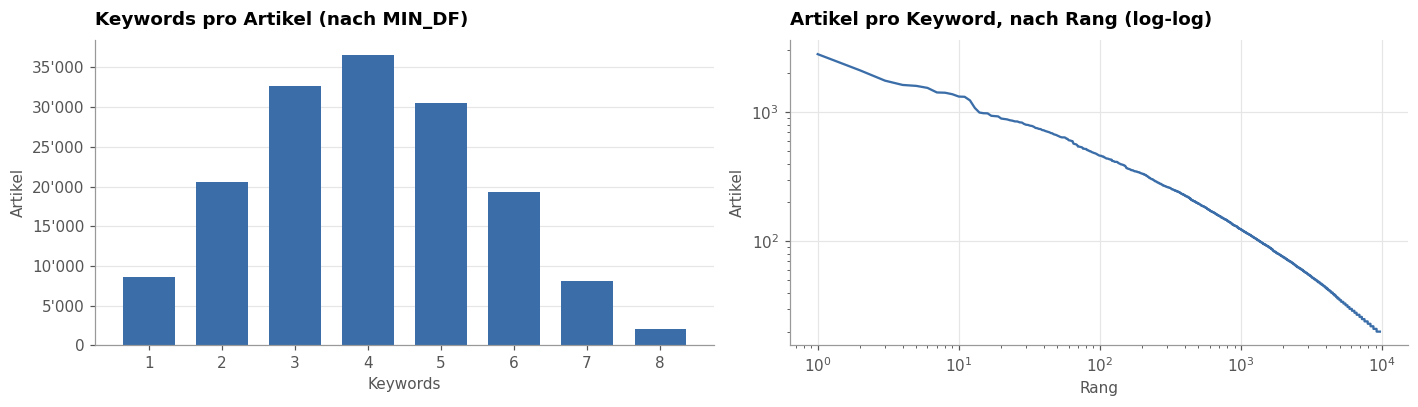

Artikel: 158,266, Keywords: 9,653, Kanten im Two-Mode-Netz: 635,317
Keywords pro Artikel (Median): 4
Häufigste Keywords: Donald Trump (2,808), Schweiz (2,102), Auto (1,751), Polizei (1,622), Zürich (1,595)


In [3]:
paare = nw.keyword_zuordnung(keywords, artikel, min_df=MIN_DF)
grad_artikel = paare.groupby("url").size()
grad_kw = paare.groupby("keyword").size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
verteilung = grad_artikel.value_counts().sort_index()
axes[0].bar(verteilung.index, verteilung.values, color=grafik.BLAU, width=0.7)
axes[0].set(title="Keywords pro Artikel (nach MIN_DF)", xlabel="Keywords", ylabel="Artikel")
axes[0].grid(axis="x", visible=False)
grafik.tausender(axes[0])
axes[1].loglog(range(1, len(grad_kw) + 1), grad_kw.values, color=grafik.BLAU)
axes[1].set(title="Artikel pro Keyword, nach Rang (log-log)", xlabel="Rang", ylabel="Artikel")
plt.tight_layout()
plt.show()

print(f"Artikel: {paare['url'].nunique():,}, Keywords: {len(grad_kw):,}, Kanten im Two-Mode-Netz: {len(paare):,}")
print(f"Keywords pro Artikel (Median): {grad_artikel.median():.0f}")
print("Häufigste Keywords:", ", ".join(f"{k} ({n:,})" for k, n in grad_kw.head(5).items()))

Nach dem Filter `MIN_DF = 20` bleiben 9'653 Keywords und 158'266 Artikel. Die Ticker und einige Artikel ohne häufiges Keyword
fallen weg. Pro Artikel sind es im Median nur noch 4 statt 8 Keywords. Die Hälfte der Keywords eines Artikels ist also so selten,
dass sie im Netz keine Rolle spielt. Die Verteilung der Keywords bleibt sehr ungleich: Donald Trump kommt in 2'808 Artikeln vor,
die meisten Keywords in wenigen Dutzend. Diese grossen Knoten werden in der Projektion zu Hubs.

## 2. Das projizierte Themennetz

Die Grundkennzahlen beschreiben die Gestalt des Netzes: Wie dicht ist es, zerfällt es in Teile, und wie viele Schritte
liegen zwischen zwei Themen?

Wir erwarten ein dünnes Netz (Dichte unter 1 %), in dem fast alle Keywords zu einer grossen Komponente gehören.
Die Wege sollten kurz sein (wenige Schritte) und das Clustering hoch, also eine „Small World“.

In [4]:
G = nw.keyword_netz(keywords, artikel, min_df=MIN_DF, min_anzahl=MIN_ANZAHL, gewicht=GEWICHT)
louvain = nw.communities(G, methode="louvain")
werte = nw.kennzahlen(G)

BESCHRIFTUNG = {"knoten": "Knoten (Keywords)", "kanten": "Kanten", "dichte": "Dichte", "komponenten": "Komponenten",
                "isolierte": "isolierte Knoten", "giant_anteil": "Anteil in grösster Komponente",
                "grad_mittel": "mittlerer Grad", "grad_max": "maximaler Grad", "clustering": "Clustering (Mittel)",
                "transitivitaet": "Transitivität", "durchmesser": "Durchmesser", "pfadlaenge_mittel": "mittlere Pfadlänge",
                "grad_zentralisierung": "Grad-Zentralisierung"}
# Durchmesser und Pfadlänge exakt zu berechnen, dauert bei fast 10'000 Knoten zu lange.
# Wir schätzen die mittlere Pfadlänge mit Breitensuchen von 300 zufälligen Startknoten aus.
giant = nw.groesste_komponente(G)
start = pd.Series(list(giant)).sample(300, random_state=42)
laengen = [l for s in start for l in nw.nx.single_source_shortest_path_length(giant, s).values() if l > 0]
werte["pfadlaenge_mittel"] = np.mean(laengen)
werte["durchmesser"] = max(laengen)  # untere Schranke

BESCHRIFTUNG["pfadlaenge_mittel"] = "mittlere Pfadlänge (geschätzt)"
BESCHRIFTUNG["durchmesser"] = "Durchmesser (mindestens)"
pd.Series(werte).rename(BESCHRIFTUNG).map(lambda x: f"{x:,.4f}".rstrip("0").rstrip(".")).to_frame("Themennetz")

,Themennetz
Knoten (Keywords),"9,653"
Kanten,"65,495"
Dichte,0.0014
Komponenten,522
isolierte Knoten,518
Anteil in grösster Komponente,0.9457
mittlerer Grad,13.5699
maximaler Grad,830
Clustering (Mittel),0.3796
Transitivität,0.1012


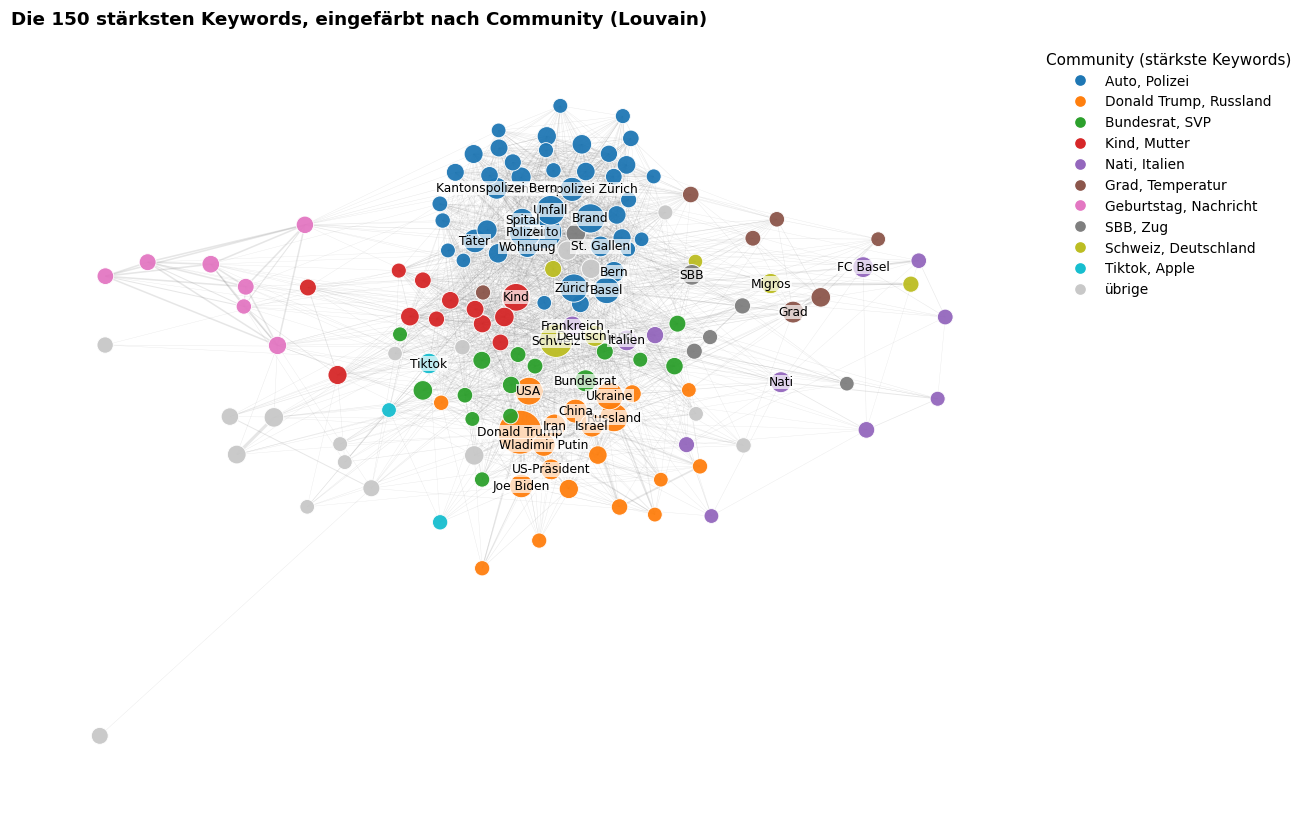

In [5]:
# Communities nach ihren zwei stärksten Keywords benennen (Abschnitt 6 zeigt sie ausführlich)
community_namen = {i: ", ".join(t.split(", ")[:2]) for i, t in nw.community_tabelle(G, louvain["gruppen"], top=2)["top"].items()}

fig, ax = plt.subplots(figsize=(12, 9))
grafik.netz_zeichnen(G, ax=ax, top=150, farbe="community", beschriftung=35, legende_titel="Community (stärkste Keywords)",
                     namen=community_namen, titel="Die 150 stärksten Keywords, eingefärbt nach Community (Louvain)")
plt.show()

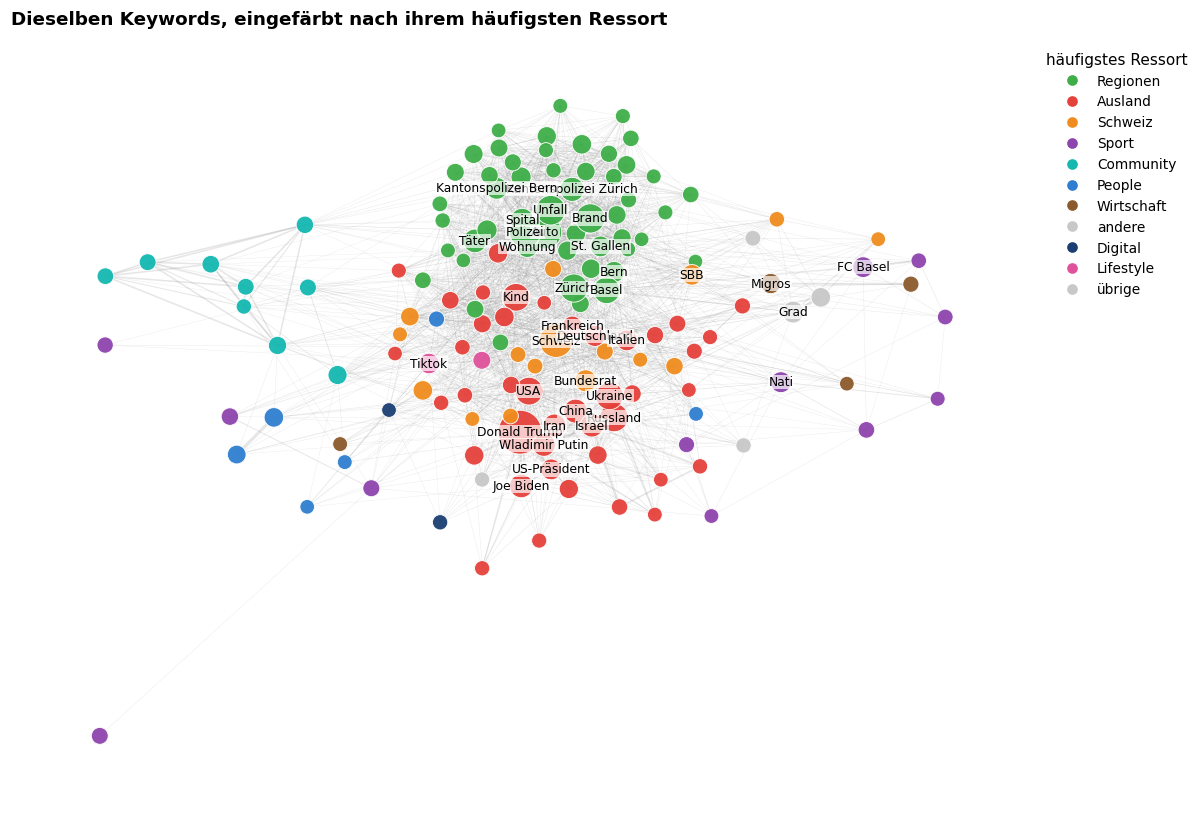

In [6]:
fig, ax = plt.subplots(figsize=(12, 9))
grafik.netz_zeichnen(G, ax=ax, top=150, farbe="ressort", beschriftung=35, legende_titel="häufigstes Ressort",
                     titel="Dieselben Keywords, eingefärbt nach ihrem häufigsten Ressort")
plt.show()

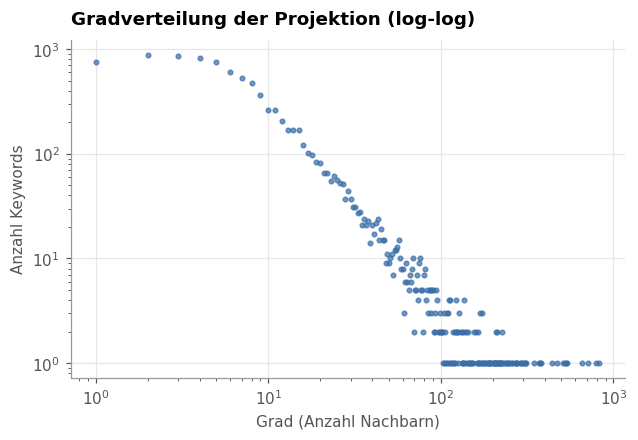

In [7]:
grade = pd.Series(dict(G.degree()))
verteilung = grade[grade > 0].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(verteilung.index, verteilung.values, marker="o", linestyle="none", markersize=3, color=grafik.BLAU, alpha=0.7)
ax.set(title="Gradverteilung der Projektion (log-log)", xlabel="Grad (Anzahl Nachbarn)", ylabel="Anzahl Keywords")
plt.show()

Die Erwartungen bestätigen sich. Das Netz ist sehr dünn (Dichte 0,0014), aber 95 % der Keywords hängen in einer grossen Komponente
zusammen. Zwischen zwei Themen liegen im Mittel nur etwa 3,4 Schritte, und das Clustering ist mit 0,38 hoch. Das ist eine typische
Small World. Wie viel vom Clustering echt ist, prüfen wir in Abschnitt 4. Die Grad-Zentralisierung ist mit 0,08 tief. Es gibt also
nicht einen einzigen Begriff, um den sich alles dreht, sondern mehrere Hubs.

Die beiden Zeichnungen sehen fast gleich aus, was schon auf H2 hinweist. Oben liegt ein dichter Block aus Polizei, Unfall und
Ortsnamen (Regionen), unten die internationale Politik um Donald Trump, Russland und die Ukraine (Ausland). Dazwischen liegen die
Schweizer Politik (Bundesrat, SVP) und Familienthemen. Der Sport (Nati, FC Basel) hängt nur lose am Rand. Links liegt eine kleine,
abgetrennte Gruppe („Geburtstag, Nachricht“). Sie stammt aus der Rubrik «BISCH ES DU?», deren Artikel immer gleich aufgebaut sind,
und ist kein eigenes Themenfeld.

Die Gradverteilung fällt im log-log-Plot ungefähr gerade ab: wenige Hubs, sehr viele Randbegriffe.

## 3. Welches Kantengewicht?

Die Wahl des Gewichts entscheidet, welche Verbindungen als „stark“ gelten. Die reine Kookkurrenz bevorzugt häufige
Begriffe, weil sie einfach öfter vorkommen. Salton teilt durch die Häufigkeit beider Begriffe und findet damit Paare,
die fast nur zusammen auftreten. Newman liegt dazwischen.

Wir erwarten, dass bei der Kookkurrenz Paare mit „Schweiz“ oder „Polizei“ oben stehen und bei Salton sehr spezifische
Paare wie Vorname und Nachname oder ein Club und sein Stadion.

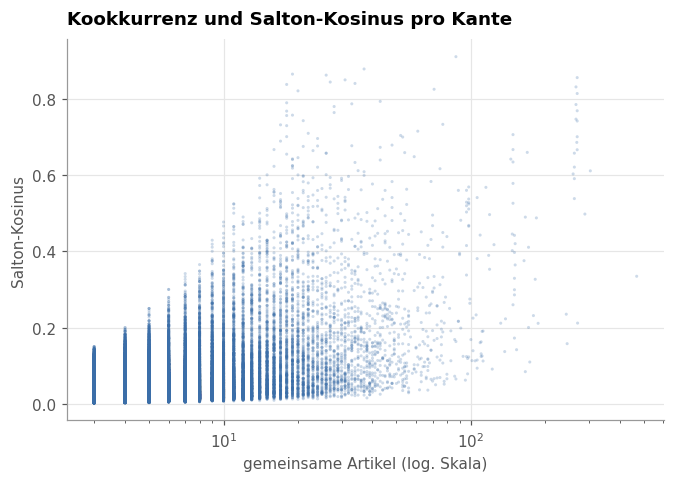

Rangkorrelation Kookkurrenz–Salton: 0.42


,anzahl,newman,salton
1,US-Präsident – Donald Trump,US-Präsident – Donald Trump,Charles Linsmayer – Literaturkolumne
2,Meghan – Prinz Harry,Meghan – Prinz Harry,Foto-Challeng – Lade hier deine Video
3,Temperatur – Grad,Ukraine – Russland,Sophie Turner – Joe Jonas
4,Ukraine – Russland,Russland – Wladimir Putin,Brian Laundrie – Gabby Petito
5,Grosi – Ausgang,Temperatur – Grad,Grosi – Ausgang
6,Grosi – Nachricht,Joe Biden – Donald Trump,Sommerzeit – Zeitumstellung
7,Grosi – Unbekannten,Musk – Elon Musk,Weltmacht – Zhao
8,Unbekannten – Ausgang,Hamas – Israel,Christian Ulme – Collien Fernandes
9,Unbekannten – Nachricht,Taliban – Afghanistan,Zivadiliring – Maja Zivadinovic
10,Nachricht – Ausgang,Iran – Teheran,Grosi – Botschaft


In [8]:
kanten = nw.nx.to_pandas_edgelist(G)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(kanten["anzahl"], kanten["salton"], s=4, alpha=0.25, color=grafik.BLAU, edgecolors="none")
ax.set(xscale="log", title="Kookkurrenz und Salton-Kosinus pro Kante",
       xlabel="gemeinsame Artikel (log. Skala)", ylabel="Salton-Kosinus")
plt.show()

print(f"Rangkorrelation Kookkurrenz–Salton: {kanten['anzahl'].corr(kanten['salton'], method='spearman'):.2f}")
pd.concat({g: kanten.nlargest(10, g)[["source", "target"]].agg(" – ".join, axis=1).reset_index(drop=True)
           for g in nw.GEWICHTE}, axis=1).rename(index=lambda i: i + 1)

Die Gewichte betonen tatsächlich verschiedene Kanten (Rangkorrelation nur 0,42). Bei der Kookkurrenz stehen erwartungsgemäss
häufige Paare oben, etwa US-Präsident und Donald Trump, aber auch „Grosi – Ausgang – Unbekannten – Nachricht“. Diese Wörter kommen
aus den immer gleich aufgebauten Artikeln der Rubrik «BISCH ES DU?». Newman zeigt die grossen inhaltlichen Paare (Ukraine – Russland,
Hamas – Israel, Taliban – Afghanistan). Salton findet sehr spezifische Paare wie Sophie Turner und Joe Jonas oder Sommerzeit und
Zeitumstellung, aber auch Textbausteine („Foto-Challeng – Lade hier deine Video“).

Newman als Hauptgewicht bestätigt sich damit: Es schwächt die Serienartikel ab, ohne häufige Begriffe ganz zu bestrafen.
Die Textbausteine sollten wir in einem nächsten Schritt als Stoppwörter aus der Keyword-Extraktion entfernen.

## 4. Ist das Clustering echt?

In der Projektion verbindet jeder Artikel alle seine Keywords miteinander. Jeder Artikel erzeugt also eine kleine Clique.
Dadurch ist das Clustering einer Projektion immer hoch, auch wenn die Themen zufällig kombiniert wären. Um zu sehen,
wie viel davon echt ist, vergleichen wir mit einem Nullmodell: Wir verteilen die Keywords zufällig neu auf die Artikel.
Jeder Artikel behält seine Anzahl Keywords und jedes Keyword seine Häufigkeit (Konfigurationsmodell).

Wenn die Themen nicht zufällig kombiniert werden, sollte das echte Netz weniger Kanten haben (dieselben Begriffe
treffen immer wieder aufeinander) und ein höheres gewichtetes Clustering als das Zufallsnetz.

Auf allen Artikeln dauert ein Zufallsnetz über zehn Minuten. Wir rechnen den Vergleich deshalb auf einer Zufallsstichprobe
von 20'000 Artikeln. Echtes Netz und Zufallsnetze beruhen auf denselben Artikeln, der Vergleich bleibt also fair.

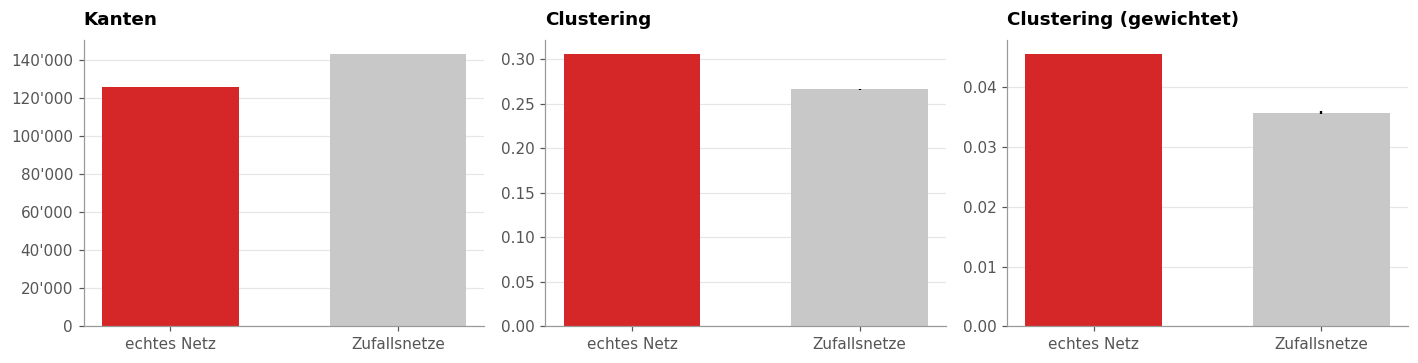

,echt,Zufall (Mittel aus 5)
kanten,125635.0000,143097.2000
clustering,0.3062,0.2662
clustering_gewichtet,0.0456,0.0358


In [9]:
auswahl = paare["url"].drop_duplicates().sample(min(20000, paare["url"].nunique()), random_state=42)
nullmodell = nw.nullmodell_clustering(paare[paare["url"].isin(auswahl)], "keyword", wiederholungen=5, min_anzahl=1)
zufall = nullmodell[nullmodell["netz"] != "echt"]
echt = nullmodell[nullmodell["netz"] == "echt"].iloc[0]
TITEL = {"kanten": "Kanten", "clustering": "Clustering", "clustering_gewichtet": "Clustering (gewichtet)"}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, spalte in zip(axes, TITEL):
    ax.bar(["echtes Netz", "Zufallsnetze"], [echt[spalte], zufall[spalte].mean()],
           yerr=[0, zufall[spalte].std()], color=[grafik.AKZENT, grafik.GRAU], width=0.6)
    ax.set(title=TITEL[spalte])
    ax.grid(axis="x", visible=False)
grafik.tausender(axes[0])
plt.tight_layout()
plt.show()

pd.DataFrame({"echt": echt[list(TITEL)], "Zufall (Mittel aus 5)": zufall[list(TITEL)].mean()}).astype(float).round(4)

Das echte Netz hat weniger Kanten als die Zufallsnetze (126'000 gegenüber 143'000). Dieselben Begriffe treffen also immer wieder
aufeinander, statt sich beliebig zu mischen. Das Clustering liegt aber nur wenig über dem Zufall (0,31 gegenüber 0,27, gewichtet
0,046 gegenüber 0,036). Der grösste Teil des hohen Clusterings aus Abschnitt 2 ist also ein Effekt der Projektion und kein Befund
über die Berichterstattung. Das ist eine wichtige Einschränkung, die wir in der Präsentation zeigen sollten. Der Vergleich beruht
auf einer Stichprobe von 20'000 Artikeln, deshalb sind die absoluten Werte kleiner als im Gesamtnetz.

## 5. Zentrale Begriffe

Zentralitätsmasse beantworten verschiedene Fragen. Die **Stärke** (gewichteter Grad) zeigt, wie oft ein Begriff mit
anderen zusammen vorkommt, also die Dauerbrenner. Die **Betweenness** zeigt, ob ein Begriff auf den Wegen zwischen
verschiedenen Themenfeldern liegt. Für H2 interessieren uns ausserdem Begriffe, die häufig sind, aber nicht zu einem
einzelnen Ressort gehören. Sie verbinden die Ressorts inhaltlich.

Wir erwarten Länder und Institutionen (Schweiz, Bund, Polizei) als stärkste Begriffe. Als Brücken vermuten wir
Begriffe, die in mehreren Ressorts vorkommen, etwa Corona, Geld oder Kinder.

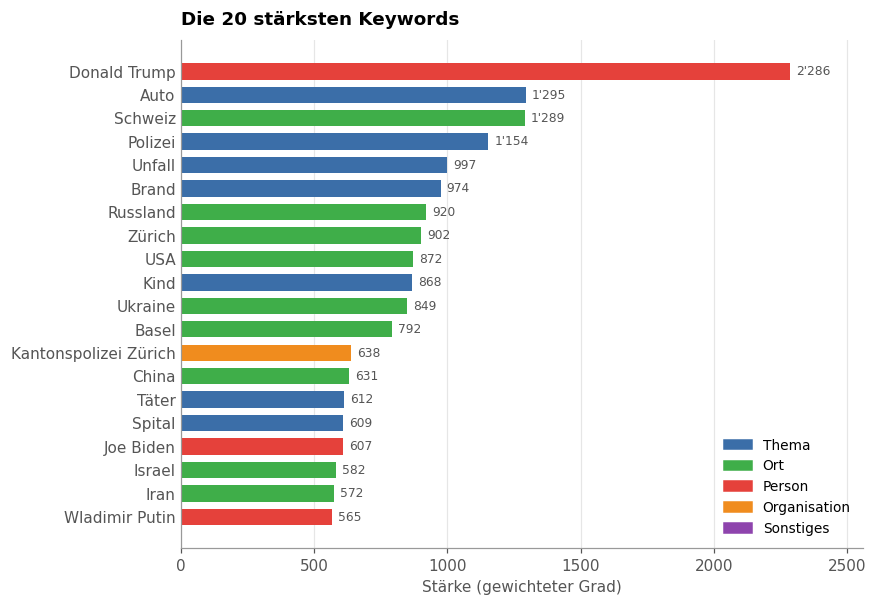

Rangkorrelation Stärke–Betweenness: 0.64
Höchste Betweenness: Schweiz, Donald Trump, Kind, Auto, Zürich, Polizei, Basel, USA, Iran, Bundesrat


In [10]:
zentral = nw.zentralitaeten(G)
top20 = zentral.head(20)

fig, ax = plt.subplots(figsize=(8, 6))
grafik.balken(top20["staerke"], ax=ax, fmt="{:,.0f}", titel="Die 20 stärksten Keywords",
              xlabel="Stärke (gewichteter Grad)", farbe=[grafik.TYP_FARBEN.get(t, grafik.GRAU) for t in top20["typ"].iloc[::-1]])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=f) for f in grafik.TYP_FARBEN.values()],
          labels=["Thema", "Ort", "Person", "Organisation", "Sonstiges"], loc="lower right")
plt.show()

print(f"Rangkorrelation Stärke–Betweenness: {zentral['staerke'].corr(zentral['betweenness'], method='spearman'):.2f}")
print("Höchste Betweenness:", ", ".join(zentral["betweenness"].nlargest(10).index))

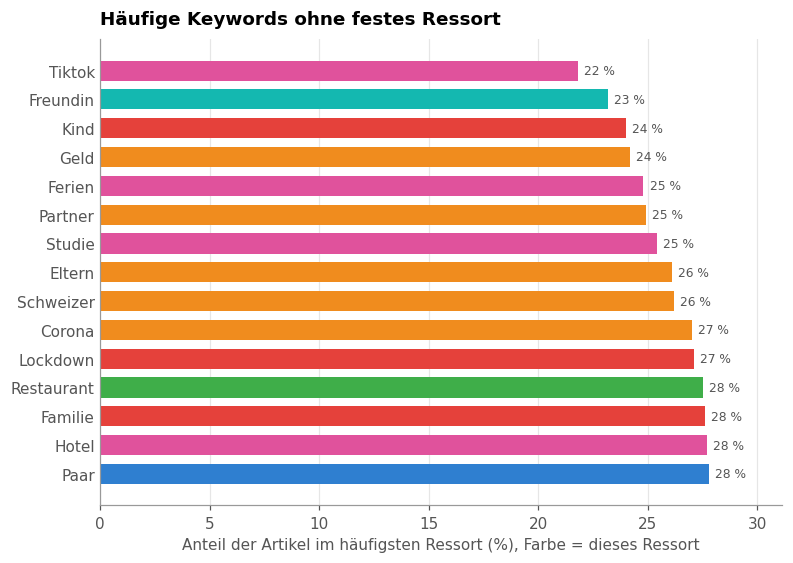

In [11]:
# Häufige Begriffe, deren Artikel sich auf viele Ressorts verteilen:
# unter den 300 stärksten Keywords die mit dem kleinsten Anteil ihres häufigsten Ressorts
staerkste = zentral.head(300).copy()
staerkste["ressort_anteil"] = pd.Series(nw.nx.get_node_attributes(G, "ressort_anteil"))
uebergreifend = staerkste.nsmallest(15, "ressort_anteil")

fig, ax = plt.subplots(figsize=(8, 5.5))
grafik.balken(uebergreifend["ressort_anteil"] * 100, ax=ax, fmt="{:.0f} %",
              farbe=[grafik.RESSORT_FARBEN.get(r, grafik.GRAU) for r in uebergreifend["ressort"].iloc[::-1]],
              titel="Häufige Keywords ohne festes Ressort",
              xlabel="Anteil der Artikel im häufigsten Ressort (%), Farbe = dieses Ressort")
plt.show()

Die stärksten Begriffe sind Donald Trump, Auto, Schweiz und Polizei, gefolgt von Unfall, Brand, Russland und Zürich. Das passt zur
Erwartung, nur dass Unfälle und Polizeimeldungen noch prominenter sind als gedacht. Stärke und Betweenness hängen eng zusammen
(Rangkorrelation 0,64): Die grossen Hubs liegen auch auf den meisten Wegen. Einen eigenständigen Brückenbegriff mit hoher
Betweenness und geringer Stärke finden wir nicht. Die Betweenness ist bei fast 10'000 Knoten allerdings nur über 500 Startknoten
geschätzt.

Aufschlussreicher sind die häufigen Begriffe ohne festes Ressort. Bei Tiktok, Kind, Geld, Ferien, Eltern, Corona oder Lockdown
stammen höchstens 28 % der Artikel aus demselben Ressort. Das sind Alltagsthemen, die in fast allen Ressorts vorkommen. Wenn die
Ressorts inhaltlich verbunden sind, dann über solche Begriffe.

## 6. Themencluster

Die Community-Erkennung sucht Gruppen von Keywords, die untereinander enger verbunden sind als mit dem Rest. Das sind
Themenfelder, die sich aus den Daten ergeben, ohne Vorgabe der Redaktion. Wir vergleichen Louvain mit Label Propagation,
um zu sehen, ob das Ergebnis vom Verfahren abhängt.

Wir erwarten bei Louvain eine Modularität über 0,5 und erkennbare grosse Cluster (Unfälle, Corona, Fussball, US-Politik).
Label Propagation dürfte mehr und kleinere Gruppen liefern.

Louvain:             542 Communities, Modularität 0.64
Label Propagation:   804 Communities, Modularität 0.42
Die 10 grössten Louvain-Communities enthalten 80% der Keywords


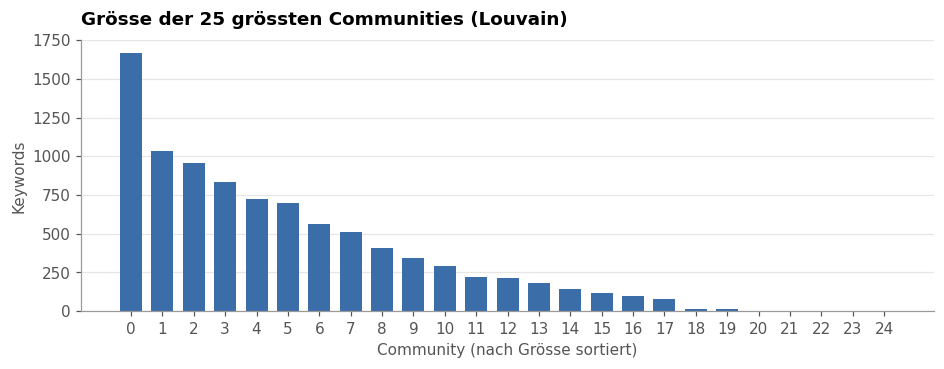

,community,Keywords,häufigstes Ressort,stärkste Keywords
0,0,1667,Regionen,"Auto, Polizei, Unfall, Brand, Zürich, Basel, Kantonspolizei Zürich, Täter"
1,1,1037,Ausland,"Donald Trump, Russland, USA, Ukraine, China, Joe Biden, Israel, Iran"
2,2,959,Schweiz,"Bundesrat, SVP, Studie, Bund, Coronavirus, Quarantäne, Österreich, Kanton"
3,3,835,Sport,"Nati, Italien, FC Basel, Frankreich, Spanien, Granit Xhaka, Cristiano Ronaldo, YB"
4,4,722,Wirtschaft,"Schweiz, Deutschland, Migros, Schweizer, Coop, Restaurant, Preis, Ferien"
5,5,699,People,"Kind, Mutter, Beziehung, Eltern, Sohn, Schule, Vater, Sex"
6,6,561,People,"Song, ESC, Taylor Swift, Fan, Konzert, Sängerin, Netflix, Hochzeit"
7,7,512,Regionen,"Grad, Temperatur, Meter, Lade hier deine Bild, Schnee, Tod, Wetter, Gewitter"
8,8,409,Ausland,"SBB, Zug, Passagier, Flugzeug, Flughafen, Swiss, Störung, Flug"
9,9,345,Lifestyle,"Tiktok, Apple, KI, Instagram, Nutzer, Haar, Facebook, Handy"


In [12]:
lpa = nw.communities(G.copy(), methode="label_propagation")
tabelle = nw.community_tabelle(G, louvain["gruppen"])
groessen = pd.Series([len(g) for g in louvain["gruppen"]])

print(f"Louvain:           {louvain['anzahl']:>5} Communities, Modularität {louvain['modularitaet']:.2f}")
print(f"Label Propagation: {lpa['anzahl']:>5} Communities, Modularität {lpa['modularitaet']:.2f}")
print(f"Die 10 grössten Louvain-Communities enthalten {groessen.head(10).sum() / groessen.sum():.0%} der Keywords")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(groessen.head(25))), groessen.head(25), color=grafik.BLAU, width=0.7)
ax.set(title="Grösse der 25 grössten Communities (Louvain)", xlabel="Community (nach Grösse sortiert)", ylabel="Keywords")
ax.set_xticks(range(len(groessen.head(25))))
ax.grid(axis="x", visible=False)
plt.show()

tabelle.head(12).rename(columns={"groesse": "Keywords", "ressort": "häufigstes Ressort", "top": "stärkste Keywords"})

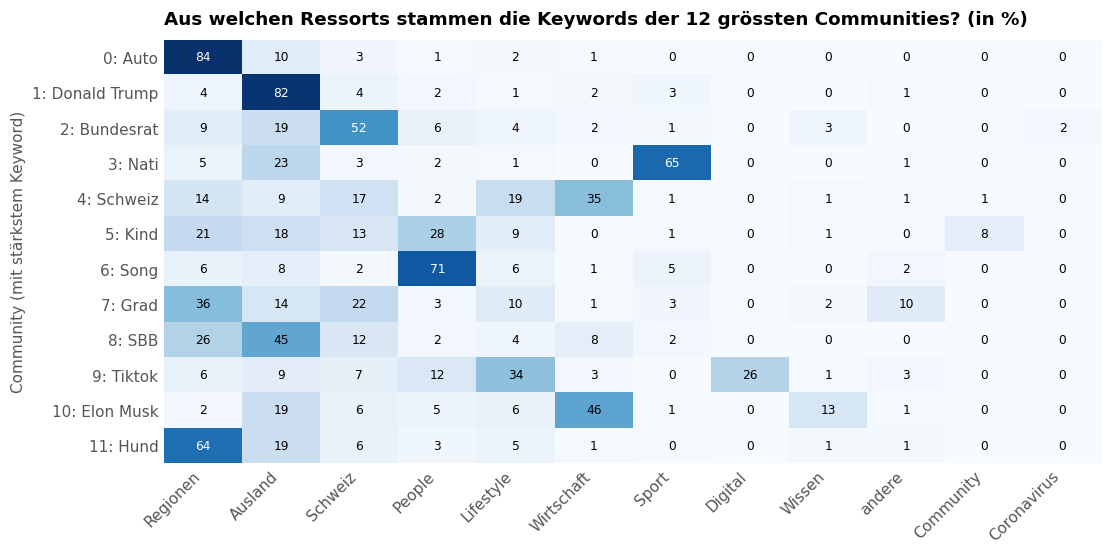

Im Mittel stammen 54% der Keywords einer Community aus demselben Ressort


In [13]:
ressort_von = nw.nx.get_node_attributes(G, "ressort")
zusammensetzung = pd.crosstab(
    pd.Series({k: G.nodes[k]["community"] for k in G}, name="community"),
    pd.Series(ressort_von, name="ressort"), normalize="index",
).loc[lambda d: d.index < 12]
zusammensetzung = zusammensetzung.loc[:, zusammensetzung.sum().sort_values(ascending=False).index]
zusammensetzung.index = [f"{i}: {tabelle.loc[i, 'top'].split(', ')[0]}" for i in zusammensetzung.index]

fig, ax = plt.subplots(figsize=(11, 5))
grafik.heatmap(zusammensetzung * 100, ax=ax, fmt="{:.0f}", titel="Aus welchen Ressorts stammen die Keywords der 12 grössten Communities? (in %)")
ax.set_ylabel("Community (mit stärkstem Keyword)")
plt.show()

print(f"Im Mittel stammen {zusammensetzung.max(axis=1).mean():.0%} der Keywords einer Community aus demselben Ressort")

Louvain findet eine klare Struktur mit einer Modularität von 0,64, Label Propagation eine deutlich schwächere (0,42). Die hohe Zahl
von 542 Communities kommt fast ganz von den 518 isolierten Keywords, die je eine eigene Community bilden. Die zehn grössten
Communities enthalten 80 % der Keywords und lassen sich gut benennen: Unfälle und Polizei, internationale Politik, Schweizer Politik
mit Corona, Fussball, Konsum (Migros, Coop, Preise), Familie und Beziehungen, Musik und Stars, Wetter, Verkehr (SBB, Flughafen),
Digitales (Tiktok, KI) sowie Tiere. Diese Namen sind unsere Deutung der stärksten Keywords.

Die Heatmap zeigt, dass einige Communities fast deckungsgleich mit einem Ressort sind: Unfälle mit Regionen (84 %),
internationale Politik mit Ausland (82 %) und Musik und Stars mit People (71 %). Andere mischen mehrere Ressorts, etwa Familie,
Wetter und Konsum. Im Mittel stammen 54 % der Keywords einer Community aus demselben Ressort.

## 7. H2: Sind die Ressorts thematische Silos?

Die Assortativität misst, ob sich Knoten mit gleichem Attribut bevorzugt verbinden (1 = nur Gleiche, 0 = wie zufällig).
Ob der Wert mehr ist als Zufall, prüfen wir mit einem Permutationstest: Wir verteilen die Ressorts 200-mal zufällig
auf die Keywords und schauen, wie oft der Zufall den beobachteten Wert erreicht. Das Ressort eines Keywords ist dabei
das Ressort, in dem es am häufigsten vorkommt.

Wenn H2 stimmt, erwarten wir eine deutlich positive Assortativität (über 0,3), die weit ausserhalb der Zufallswerte liegt.

Assortativität beobachtet: 0.563
Zufall: Mittel -0.001, Maximum 0.003
p-Wert: 0.005


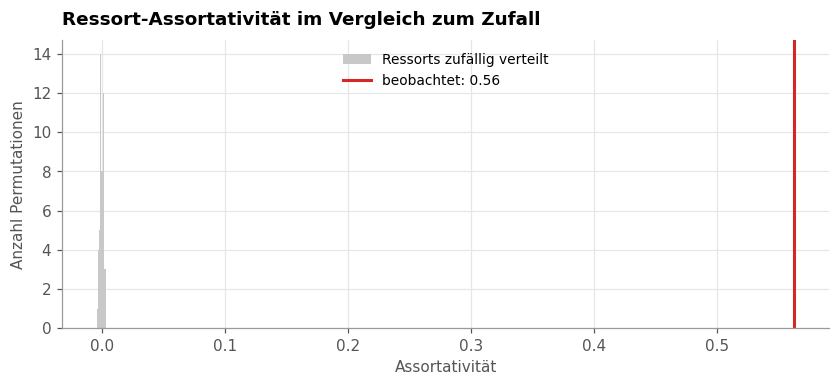

In [14]:
test = nw.assortativitaet_test(G, "ressort", permutationen=200)
print(f"Assortativität beobachtet: {test['beobachtet']:.3f}")
print(f"Zufall: Mittel {test['null_mittel']:.3f}, Maximum {test['null_max']:.3f}")
print(f"p-Wert: {test['p_wert']:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.4))
grafik.permutation_zeichnen(test, ax=ax, titel="Ressort-Assortativität im Vergleich zum Zufall")
plt.show()

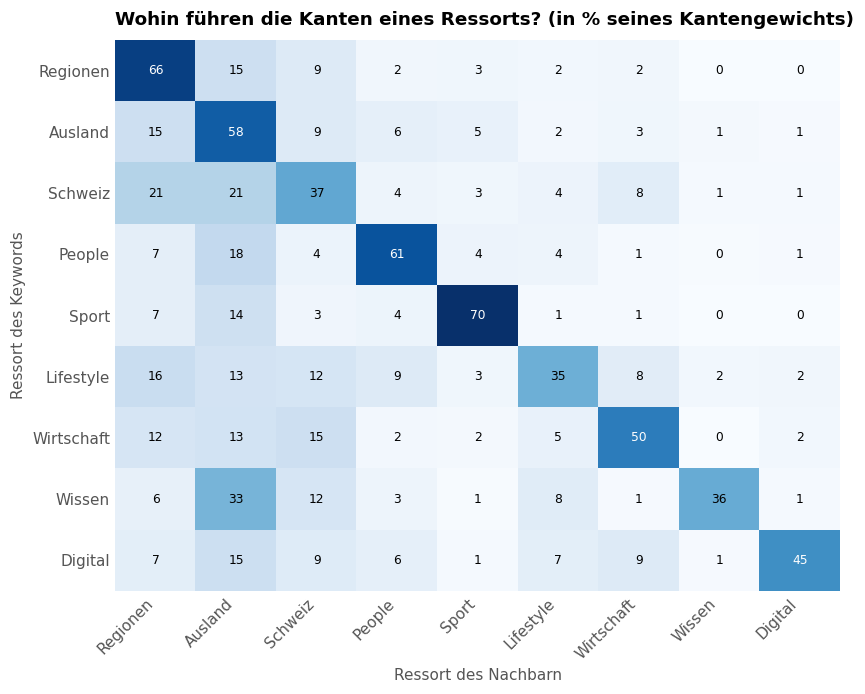

Kantengewicht innerhalb desselben Ressorts: 58%


In [15]:
r = nw.nx.get_node_attributes(G, "ressort")
k = kanten.assign(a=kanten["source"].map(r), b=kanten["target"].map(r))
haupt = [x for x in pd.Series(list(r.values())).value_counts().index if x != "andere"][:9]
k = k[k["a"].isin(haupt) & k["b"].isin(haupt)]
matrix = k.pivot_table(index="a", columns="b", values="weight", aggfunc="sum", fill_value=0)
matrix = matrix.reindex(index=haupt, columns=haupt, fill_value=0)
matrix = matrix + matrix.T - np.diag(np.diag(matrix))  # ungerichtet: beide Richtungen zusammenzählen
anteil_zeile = matrix.div(matrix.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8.5, 6.5))
grafik.heatmap(anteil_zeile, ax=ax, fmt="{:.0f}", titel="Wohin führen die Kanten eines Ressorts? (in % seines Kantengewichts)")
ax.set(xlabel="Ressort des Nachbarn", ylabel="Ressort des Keywords")
plt.show()

print(f"Kantengewicht innerhalb desselben Ressorts: {np.trace(matrix.values) / matrix.values.sum():.0%}")

H2 wird gestützt. Die Ressort-Assortativität liegt bei 0,56, während der Zufall nie über 0,003 kommt (p = 0,005, der kleinste
mögliche Wert bei 200 Permutationen). 58 % des Kantengewichts verbinden Keywords desselben Ressorts. Ein Teil davon ist allerdings
eingebaut: Das Ressort eines Keywords ist das Ressort, in dem es am häufigsten vorkommt.

Die Matrix zeigt, wie unterschiedlich geschlossen die Ressorts sind. Sport (70 %), Regionen (66 %), People (61 %) und Ausland
(58 %) sind am stärksten unter sich. Schweiz, Lifestyle und Wissen sind dagegen offen. Wissen hat ein Drittel seines Kantengewichts
mit Ausland, Schweiz je ein Fünftel mit Regionen und Ausland. Ausland ist für fast alle Ressorts der wichtigste Nachbar. Wir lesen
das so: Die Ressorts sind Silos, aber keine geschlossenen. Die Verbindungen laufen über Ausland und über Alltagsbegriffe (Abschnitt 5).

## 8. H1: Konzentrieren Krisenjahre die Agenda?

Wenn eine Krise die Berichterstattung beherrscht, sollte sich das Themennetz um wenige Begriffe zusammenziehen: Die
Grad-Zentralisierung steigt und die Modularität sinkt. Dichte und Clustering hängen stark von der Grösse eines Netzes ab.
Damit der Vergleich fair ist, ziehen wir deshalb pro Jahr gleich viele Artikel.

Wir erwarten, dass 2020 (Covid) und 2022 (Ukraine) bei der Zentralisierung vorne liegen und dass sich die zentralen
Begriffe in diesen Jahren sichtbar verschieben.

In [16]:
stichprobe = nw.stichprobe_pro_jahr(artikel)
n_pro_jahr = int(stichprobe["jahr"].value_counts().min())
min_df_jahr = max(3, MIN_DF // 4)
zeilen, jahresnetze, staerken = [], {}, {}
for jahr in sorted(stichprobe["jahr"].unique()):
    g = nw.keyword_netz(keywords, stichprobe, jahre=[jahr], min_df=min_df_jahr, min_anzahl=2, gewicht=GEWICHT)
    jahresnetze[jahr] = g
    werte_jahr = nw.kennzahlen(g, durchmesser_bis=0)
    werte_jahr["modularitaet"] = nw.communities(g.copy())["modularitaet"]
    staerken[jahr] = pd.Series(dict(g.degree(weight="weight")))
    werte_jahr["stärkste Begriffe"] = ", ".join(staerken[jahr].nlargest(5).index)
    zeilen.append({"jahr": jahr, **werte_jahr})
jahre_tabelle = pd.DataFrame(zeilen).set_index("jahr")

print(f"{n_pro_jahr:,} Artikel pro Jahr, MIN_DF pro Jahr = {min_df_jahr}")
jahre_tabelle[["knoten", "kanten", "dichte", "clustering", "grad_zentralisierung", "modularitaet", "stärkste Begriffe"]].round(4)

20,338 Artikel pro Jahr, MIN_DF pro Jahr = 5


,knoten,kanten,dichte,clustering,grad_zentralisierung,modularitaet,stärkste Begriffe
jahr,,,,,,,
2020,5839,15497,0.0009,0.2982,0.0522,0.7090,"Donald Trump, Coronavirus, Auto, Quarantäne, Polizei"
2021,6031,15089,0.0008,0.2949,0.0262,0.7474,"Joe Biden, Impfung, Auto, Polizei, Donald Trump"
2022,5945,15149,0.0009,0.3040,0.0543,0.7552,"Ukraine, Russland, Wladimir Putin, China, Auto"
2023,5852,14421,0.0008,0.2987,0.0325,0.7583,"Auto, Basel, Israel, Hamas, Unfall"
2024,5868,13785,0.0008,0.2828,0.0331,0.7669,"Donald Trump, Schweiz, Israel, Kamala Harris, Polizei"
2025,5852,14096,0.0008,0.2931,0.0848,0.7490,"Donald Trump, USA, Schweiz, Zürich, Polizei"
2026,6009,15227,0.0008,0.2990,0.0413,0.7473,"Donald Trump, Iran, Crans-Montana, Schweiz, Brand"


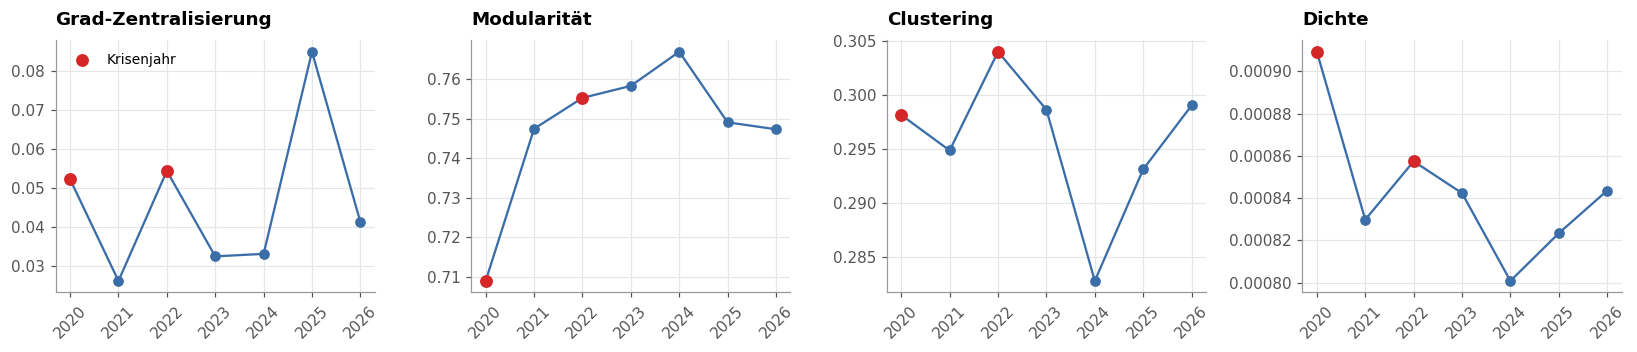

Rang bei der Zentralisierung (1 = am stärksten zentralisiert):
jahr
2020    3
2021    7
2022    2
2023    6
2024    5
2025    1
2026    4


In [17]:
KRISEN = [2020, 2022]
SPALTEN = {"grad_zentralisierung": "Grad-Zentralisierung", "modularitaet": "Modularität",
           "clustering": "Clustering", "dichte": "Dichte"}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, (spalte, titel) in zip(axes, SPALTEN.items()):
    reihe = jahre_tabelle[spalte]
    ax.plot(reihe.index, reihe.values, marker="o", color=grafik.BLAU)
    krise = reihe[reihe.index.isin(KRISEN)]
    ax.scatter(krise.index, krise.values, color=grafik.AKZENT, zorder=3, s=55, label="Krisenjahr")
    ax.set(title=titel)
    ax.set_xticks(reihe.index)
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

rang = jahre_tabelle["grad_zentralisierung"].rank(ascending=False).astype(int)
print("Rang bei der Zentralisierung (1 = am stärksten zentralisiert):")
print(rang.to_string())

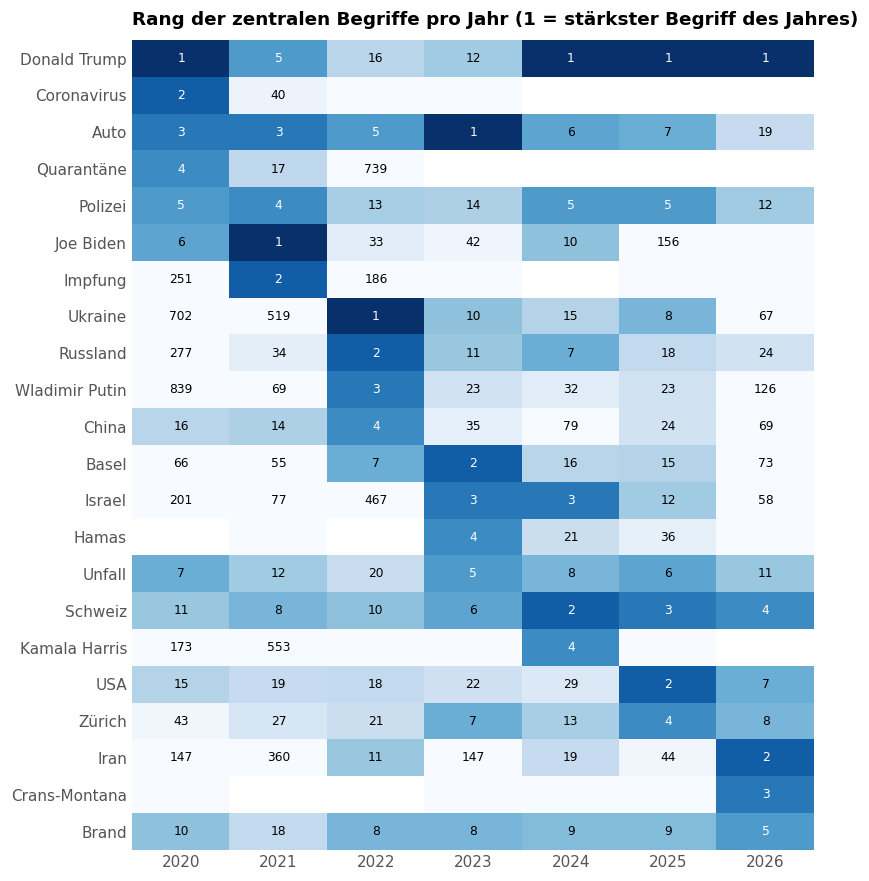

In [18]:
# Wie verschieben sich die zentralen Begriffe? Rang der wichtigsten Begriffe pro Jahr
raenge = pd.DataFrame({j: s.rank(ascending=False, method="min") for j, s in staerken.items()})
auswahl = list(dict.fromkeys(b for j in sorted(staerken) for b in staerken[j].nlargest(5).index))
tabelle_raenge = raenge.loc[auswahl]

fig, ax = plt.subplots(figsize=(8, 0.38 * len(auswahl) + 1.2))
# Farbe: Rang 1 dunkel, ab Rang 50 hell; Zahl = Rang, leer = Begriff kommt im Jahr nicht vor
grafik.heatmap(-np.log(tabelle_raenge.clip(upper=50)), ax=ax, fmt="", cmap="Blues",
               titel="Rang der zentralen Begriffe pro Jahr (1 = stärkster Begriff des Jahres)")
for i, begriff in enumerate(auswahl):
    for j, jahr in enumerate(tabelle_raenge.columns):
        rang = tabelle_raenge.loc[begriff, jahr]
        if pd.notna(rang):
            ax.text(j, i, f"{rang:.0f}" if rang < 1000 else "", ha="center", va="center", fontsize=8,
                    color="white" if rang <= 5 else "black")
plt.show()

H1 wird nur teilweise gestützt. Bei der Zentralisierung liegen 2022 auf Rang 2 und 2020 auf Rang 3, am stärksten zentralisiert ist
aber 2025. Die Rangtabelle erklärt warum: 2025 steht Donald Trump mit Abstand an der Spitze, nach seiner zweiten Amtsübernahme.
Gemessen wird also weniger eine „Krise“ als die Dominanz eines einzelnen Begriffs. Die Modularität ist 2020 am tiefsten (0,71),
die Themen sind in diesem Jahr also am stärksten verflochten. Das passt zu Corona, das in fast alle Ressorts hineinreichte.

Die Rangtabelle zeigt die Ereignisse sehr deutlich: Coronavirus und Quarantäne 2020, Impfung und Joe Biden 2021, Ukraine, Russland
und Putin 2022, Israel und Hamas 2023, Kamala Harris 2024, Iran und Crans-Montana 2026. Daneben gibt es Dauerbrenner, die jedes Jahr
oben sind: Auto, Polizei, Unfall, Brand und die Schweiz.

Mit sieben Jahren ist das kein statistischer Test, sondern ein Vergleich von Einzelwerten. Für 2020 kommt dazu, dass Corona auf
mehrere Keywords verteilt ist (Notebook 01, Abschnitt 14). Die Zentralisierung dieses Jahres ist deshalb eher unterschätzt.

## 9. Ego-Netze: Wie verändert sich das Umfeld eines Themas?

Ein Ego-Netz zeigt nur einen Begriff und seine direkten Nachbarn. Damit können wir verfolgen, in welchem Zusammenhang
ein Thema über die Jahre steht. Wir schauen uns das Coronavirus an und vergleichen die Nachbarn mit einigen anderen
Begriffen.

Wir erwarten, dass Krisenbegriffe ihre Nachbarn stark wechseln (Corona zuerst mit Wuhan und China, später mit Impfung
und Zertifikat) und Dauerthemen wie die SVP kaum.

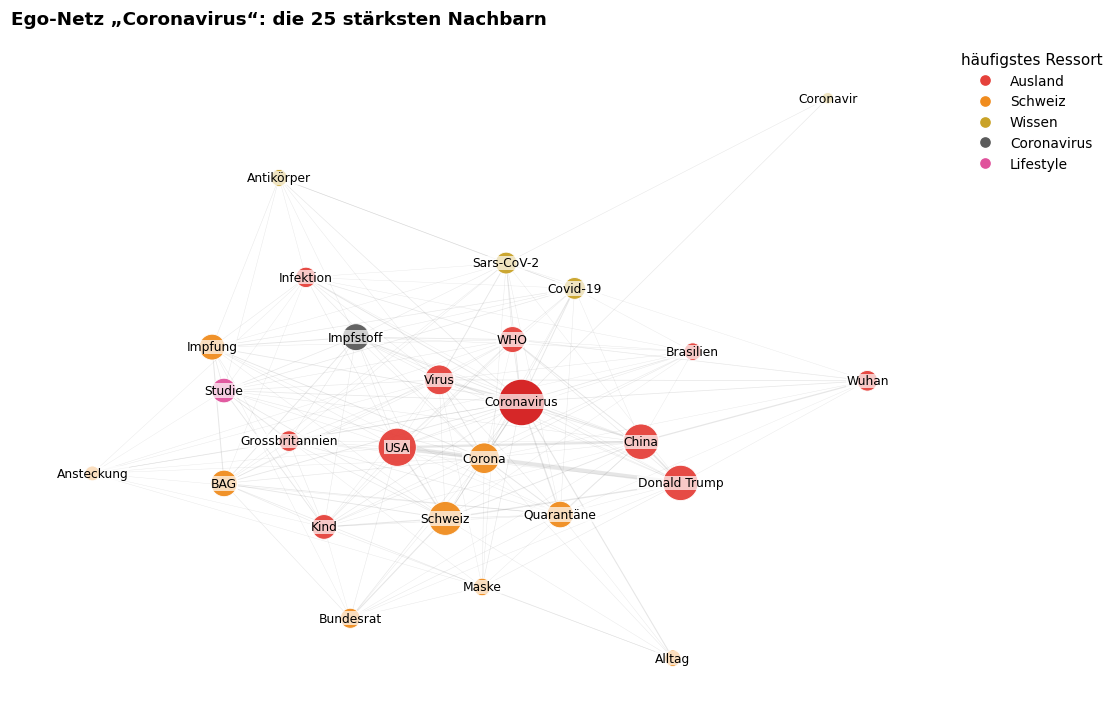

In [19]:
EGO = ["Coronavirus", "Ukraine", "SVP", "Donald Trump", "Israel"]
vorhanden = [b for b in EGO if b in G] or list(zentral.index[:1])
fokus = vorhanden[0]
ego = nw.ego_netz(G, fokus, top=25)

fig, ax = plt.subplots(figsize=(11, 8))
grafik.netz_zeichnen(ego, ax=ax, top=26, farbe="ressort", beschriftung=26, hervorheben=fokus,
                     legende_titel="häufigstes Ressort", titel=f"Ego-Netz „{fokus}“: die 25 stärksten Nachbarn")
plt.show()

In [20]:
zeilen = []
for begriff in vorhanden:
    for jahr, g in jahresnetze.items():
        if begriff in g:
            nachbarn = sorted(g[begriff].items(), key=lambda kv: kv[1]["weight"], reverse=True)[:6]
            zeilen.append({"Begriff": begriff, "Jahr": jahr, "Grad": g.degree(begriff),
                           "stärkste Nachbarn": ", ".join(n for n, _ in nachbarn)})
pd.DataFrame(zeilen).set_index(["Begriff", "Jahr"])

Grad  \
Begriff      Jahr         
Coronavirus  2020   269   
             2021    71   
             2022     9   
             2023     0   
Ukraine      2020     8   
             2021    12   
             2022   328   
             2023    87   
             2024    55   
             2025    92   
             2026    31   
SVP          2020    34   
             2021    47   
             2022    31   
             2023    72   
             2024    64   
             2025    28   
             2026    42   
Donald Trump 2020   310   
             2021    89   
             2022    57   
             2023    72   
             2024   199   
             2025   501   
             2026   253   
Israel       2020    22   
             2021    45   
             2022    13   
             2023    91   
             2024    97   
             2025    78   
             2026    49   

                                                                                    stärkste Nachbarn  
Begriff      Jahr                                                                                      
Coronavirus  2020                                  Virus, Quarantäne, China, Alltag, Corona, Covid-19  
             2021                               Impfung, Impfstoff, Corona, Schweiz, Brasilien, Virus  
             2022                                Virus, Isolation, Corona, Symptom, Österreich, China  
             2023                                                                                      
Ukraine      2020  Uefa, Nations League, Nati, Schweizer Nationalmannschaft, Quarantäne, Granit Xhaka  
             2021                             Wladimir Putin, Russland, Joe Biden, Pipeline, EU, Nato  
             2022                    Russland, Kiew, Wladimir Putin, Wolodimir Selenski, Krieg, Putin  
             2023                 Russland, Wolodimir Selenski, Kiew, Einsatz, Moskau, Wladimir Putin  
             2024                    Russland, Kursk, Wolodimir Selenski, Kiew, Wladimir Putin, Krieg  
             2025               Wolodimir Selenski, Donald Trump, Russland, Wladimir Putin, Kiew, USA  
             2026                     Russland, Wolodimir Selenski, Kiew, Krieg, Drohne, Donald Trump  
SVP          2020   Marco Chiesa, Begrenzungsinitiativ, Bundesrat, CVP, Begrenzungsinitiative, Partei  
             2021        Bundesrat, Rahmenabkommen, Covid-19-Gesetz, Partei, CO2-Gesetz, Marco Chiesa  
             2022                             JSVP, Bundesrat, Ueli Maurer, Partei, Kanton Zürich, SP  
             2023          SP, FDP, Thomas Matter, David Trachsel, Sarah Bütikofer, Klimaschutzgesetz  
             2024                     Marcel Dettling, Beat Jans, SP, Initiative, Nils Fiechter, Juso  
             2025                                       SP, FDP, Stadt Bern, Unterschrift, E-ID, Bern  
             2026         Zuwanderung, Initiative, Marcel Dettling, SVP-Initiative, Beat Jans, Partei  
Donald Trump 2020                                US-Präsident, Joe Biden, USA, Demokrat, Trump, China  
             2021                  Joe Biden, US-Präsident, Trump, Capitol, Repräsentantenhaus, Senat  
             2022               Mar-a-Lago, Capitol, Dokument, Joe Biden, Untersuchungsausschuss, FBI  
             2023                     Anklage, Jack Smith, Georgia, Trump, US-Präsident, Ron DeSantis  
             2024                Kamala Harris, Joe Biden, US-Wahl, Trump, US-Präsident, Republikaner  
             2025              US-Präsident, USA, Elon Musk, Zoll, Wolodimir Selenski, Wladimir Putin  
             2026                                 US-Präsident, Iran, USA, Grönland, Demokrat, Hormus  
Israel       2020                    Jerusalem, Benjamin Netanjahu, Emirat, Donald Trump, Syrien, VAE  
             2021    Gazastreifen, Naftali Bennett, Palästinenser, Hamas, Benjamin Netanyahu, Israeli  
             2022                  Westjordanland, Regierung, Jerusalem, Rakete, Jai

Das Ego-Netz von Coronavirus vereint die medizinische Seite (Virus, Sars-CoV-2, Impfstoff, Antikörper), die politische (BAG,
Bundesrat, Quarantäne) und die internationale (China, Wuhan, USA, Donald Trump). Die Tabelle zeigt, wie sich das Umfeld verschiebt:
2020 Quarantäne, China und Alltag, 2021 Impfung und Impfstoff, 2022 Isolation und Symptom, ab 2023 kommt das Keyword in der
Stichprobe nicht mehr vor.

Die Ukraine ist ein schönes Beispiel für einen Bedeutungswechsel: 2020 steht sie neben Nations League und Nati, es ging also um
Fussball. Ab 2021 sind ihre Nachbarn Putin, Russland und die Nato, ab 2022 Kiew, Selenski und Krieg. Bei der SVP wechseln die
Nachbarn mit den Abstimmungen und den Personen (Begrenzungsinitiative 2020, Rahmenabkommen 2021, Marcel Dettling ab 2024), die Partei
selbst bleibt aber immer im Kontext von Bundesrat und anderen Parteien. Die Erwartung bestätigt sich: Krisenbegriffe wechseln ihr
Umfeld stark, Dauerthemen wechseln vor allem die Personen.

## 10. H3: Lassen sich neue Themenverbindungen vorhersagen?

Bei der Link Prediction nehmen wir das Netz aller Vorjahre und sagen voraus, welche Keyword-Paare im nächsten Jahr neu
verbunden werden. Common Neighbors, Jaccard, Adamic-Adar und Resource Allocation zählen gemeinsame Nachbarn.
Preferential Attachment setzt nur auf grosse Knoten. Bewertet wird mit der AUC: 0,5 entspricht Raten, 1 einer perfekten
Vorhersage.

Wir erwarten, dass alle Verfahren klar über 0,5 liegen und Adamic-Adar oder Resource Allocation besser abschneiden als
Preferential Attachment, weil neue Verbindungen eher im thematischen Umfeld entstehen.

In [21]:
NAMEN = {"common_neighbors": "Common Neighbors", "jaccard": "Jaccard", "adamic_adar": "Adamic-Adar",
         "resource_allocation": "Resource Allocation", "preferential_attachment": "Preferential Attachment"}
ergebnisse = []
for jahr in JAHRE[1:]:
    alt = nw.keyword_netz(keywords, artikel, jahre=[j for j in JAHRE if j < jahr], min_df=MIN_DF, min_anzahl=MIN_ANZAHL)
    neu = nw.keyword_netz(keywords, artikel, jahre=[jahr], min_df=max(3, MIN_DF // 4), min_anzahl=2)
    tabelle_lp = nw.link_prediction(alt, neu)
    if len(tabelle_lp):
        ergebnisse.append(tabelle_lp.assign(zieljahr=jahr))
lp = pd.concat(ergebnisse)
lp["verfahren"] = lp["verfahren"].map(NAMEN)
lp.pivot_table(index="verfahren", columns="zieljahr", values="auc").round(3)

zieljahr,2021,2022,2023,2024,2025,2026
verfahren,,,,,,
Adamic-Adar,0.724,0.720,0.752,0.775,0.800,0.795
Common Neighbors,0.722,0.719,0.750,0.773,0.798,0.792
Jaccard,0.717,0.716,0.746,0.768,0.790,0.782
Preferential Attachment,0.739,0.739,0.760,0.778,0.795,0.759
Resource Allocation,0.723,0.720,0.751,0.776,0.800,0.795


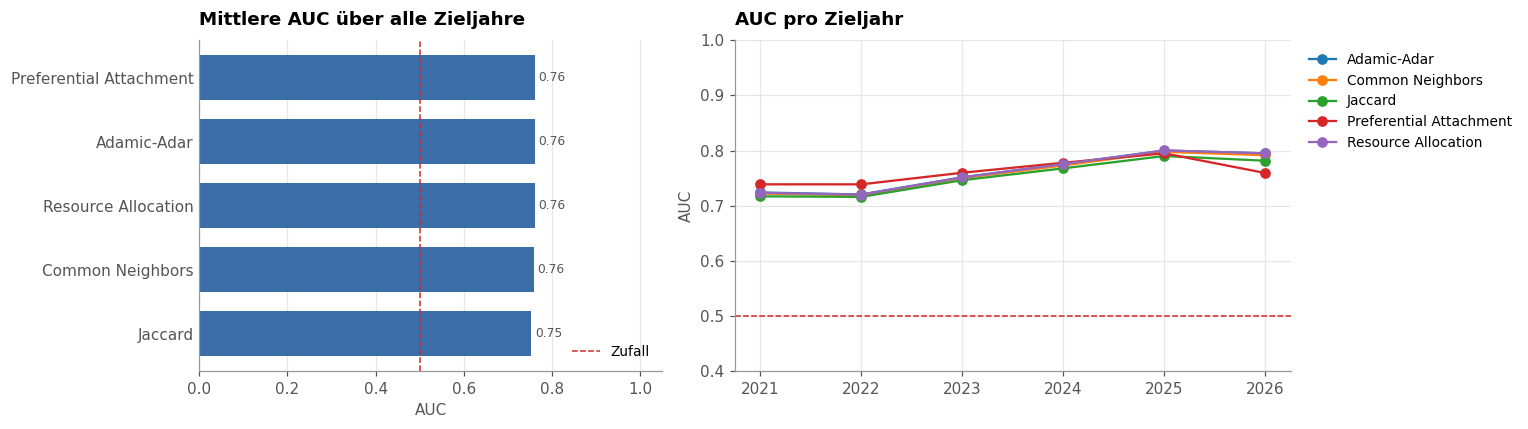

,auc,precision_at_k
verfahren,,
Preferential Attachment,0.762,0.702
Adamic-Adar,0.761,0.689
Resource Allocation,0.761,0.689
Common Neighbors,0.759,0.689
Jaccard,0.753,0.689


In [22]:
mittel = lp.groupby("verfahren")[["auc", "precision_at_k"]].mean().sort_values("auc", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.2]})
grafik.balken(mittel["auc"], ax=axes[0], fmt="{:.2f}", titel="Mittlere AUC über alle Zieljahre", xlabel="AUC",
              referenz=0.5, referenz_label="Zufall")
axes[0].set_xlim(0, 1.05)
for i, (verfahren, reihe) in enumerate(lp.pivot_table(index="zieljahr", columns="verfahren", values="auc").items()):
    axes[1].plot(reihe.index, reihe.values, marker="o", label=verfahren, color=grafik.PALETTE[i])
axes[1].axhline(0.5, color=grafik.AKZENT, linestyle="--", linewidth=1)
axes[1].set(title="AUC pro Zieljahr", ylabel="AUC", ylim=(0.4, 1))
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

mittel.round(3)

Neue Verbindungen lassen sich klar besser als zufällig vorhersagen: Alle Verfahren erreichen eine AUC um 0,76, und der Wert steigt
von 0,72 für 2021 auf etwa 0,80 für 2025, weil das Netz der Vorjahre mit der Zeit grösser wird. Der zweite Teil von H3 bestätigt sich
aber nicht. Preferential Attachment ist im Mittel gleich gut wie Adamic-Adar und Resource Allocation, in den ersten Jahren sogar etwas
besser. Erst 2026 liegen die nachbarschaftsbasierten Verfahren vorne.

Neue Themenverbindungen entstehen also vor allem dort, wo schon grosse Begriffe sind. Wer oft vorkommt, bekommt auch neue Nachbarn.
Gemeinsame Nachbarn helfen kaum zusätzlich, wahrscheinlich weil die grossen Hubs ohnehin mit fast allen gemeinsame Nachbarn haben.

## 11. Export für Gephi

Für die Darstellung in Gephi speichern wir das Netz in zwei Varianten in `Graphen/`: `keywords_gesamt` mit allen Kanten
(darauf beruhen die Kennzahlen oben) und `keywords_backbone`, in dem jeder Knoten nur seine `BACKBONE_K` stärksten
Kanten behält. Der Backbone eignet sich besser für Bilder. Dazu kommen die Jahresnetze aus Abschnitt 8 in `Graphen/jahre/`.

In [23]:
B = nw.backbone(G, BACKBONE_K)
for name, graph in {"keywords_gesamt": G, "keywords_backbone": B}.items():
    nw.exportieren(graph, GRAPHEN / name)
    print(f"{name}: {graph.number_of_nodes():,} Knoten, {graph.number_of_edges():,} Kanten")
for jahr, g in jahresnetze.items():
    nw.communities(g)
    nw.exportieren(g, GRAPHEN / "jahre" / f"keywords_{jahr}")

keywords_gesamt: 9,653 Knoten, 65,495 Kanten


keywords_backbone: 9,653 Knoten, 43,792 Kanten


## Gesamtreflexion

Das Themennetz von 20 Minuten ist eine Small World mit wenigen grossen Hubs (Donald Trump, Schweiz, Polizei, Unfall) und gut
erkennbaren Themenfeldern. Die drei Vermutungen:

- **H1** wird nur teilweise gestützt. 2020 und 2022 sind stark zentralisiert, am stärksten aber 2025, weil Donald Trump dominiert.
  Die Zentralisierung misst die Dominanz einzelner Begriffe, nicht Krisen an sich.
- **H2** wird gestützt. Die Ressorts strukturieren die Themen deutlich (Assortativität 0,56). Sport, Regionen und People sind am
  geschlossensten, Schweiz, Lifestyle und Wissen am offensten. Verbunden werden die Ressorts über Ausland und Alltagsbegriffe.
- **H3** wird nur im ersten Teil gestützt. Neue Verbindungen sind vorhersagbar (AUC 0,76), aber die Grösse der Knoten erklärt sie
  ebenso gut wie gemeinsame Nachbarn.

Grenzen: Das Clustering ist zum grössten Teil ein Effekt der Projektion (Nullmodell). Corona ist auf mehrere Keywords verteilt.
Textbausteine und Serienartikel («BISCH ES DU?», „Lade hier deine Bild“) erzeugen künstliche Verbindungen, und die Ressorts sind
redaktionelle Etiketten. Als Nächstes würden wir die Varianten zusammenführen und die Textbausteine als Stoppwörter entfernen.